# PhisGuard: Email Threat Classification Engine
Notebook Eksperimen dan Pipeline Klasifikasi Email Phishing

---

### Informasi Proyek dan Roadmap Model
* Domain: Natural Language Processing (NLP) / Email Threat Detection
* Target Model (Production): TF-IDF + Linear SVM (LinearSVC / SGDClassifier loss hinge)
* Baseline Model: TF-IDF + Logistic Regression
* Nama Dataset: Phishing Email Dataset
* Sumber Repository: Hugging Face ([zefang-liu/phishing-email-dataset](https://huggingface.co/datasets/zefang-liu/phishing-email-dataset))
* Asal Usul Korpus: Mirror dataset Kaggle "Phishing Email Detection" oleh Cyber Cop (Enron Corpus, Nazario Corpus, SpamAssassin, Nigerian Fraud 419, Ling-Spam, CEAS)

---
### Struktur Notebook
1. CHAPTER 1 : Dataset Quality Audit
2. CHAPTER 2 : Data Cleaning & Text Preprocessing
3. CHAPTER 3 : Model Training & Evaluation (Tahap Selanjutnya)


# CHAPTER 1 : Dataset Quality Audit

Bab ini berfokus pada audit komprehensif korpus teks Phishing Email Dataset:
1. Integritas korpus teks mentah, missing values, dan entri whitespace kosong.
2. Identifikasi baris anomali raksasa (dump notebook baris 12500 sebesar 17 MB).
3. Deteksi konflik label pada template teks literal "empty" (335 Phish vs 198 Safe).
4. Evaluasi distribusi target dan ketidakseimbangan kelas.
5. Analisis statistik tendensi sentral panjang karakter dan jumlah kata (Mean vs Median gap).
6. Prevalensi tag HTML, URL, dan artefak struktural.
7. Analisis risiko bias domain Enron vs Nazario (Clever Hans Effect).


## 1.1 Problem Framing & NLP Decision Canvas (/data-question-framing)

* Unit of Analysis: Satu pesan email teks mentah.
* Target Definition: Kolom Email Type (Safe Email vs Phishing Email).
* Biaya Kesalahan: False Positive (email bisnis sah dikarantina) sangat merugikan operasional, sehingga Precision pada Safe Email harus dijaga sangat tinggi tanpa mengorbankan Recall deteksi Phishing.
* Justifikasi Model: Fitur TF-IDF berdimensi tinggi (> 20.000 token n-gram) optimal dipisahkan oleh Linear SVM (maximum margin hyperplane) dengan kecepatan inferensi tinggi untuk mail gateway.


## 1.2 Environment Setup & Data Ingestion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from collections import Counter
import re
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', font='sans-serif')
palette = {'Phishing Email': '#e74c3c', 'Safe Email': '#3498db'}

DATA_PATH = Path('data/email/raw/phishing_email.csv')
PLOT_DIR = Path('plots/email')
PLOT_DIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(DATA_PATH)
print("Dataset Phishing Email mentah berhasil dimuat.")
print(f"Dimensi Data: {df_raw.shape[0]:,} baris, {df_raw.shape[1]} kolom.")
df_raw.head(3)


Dataset Phishing Email mentah berhasil dimuat.
Dimensi Data: 18,650 baris, 3 kolom.


,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email


## 1.3 Schema & Structural Column Inspection

In [2]:
schema_df = pd.DataFrame({
    'Column': df_raw.columns,
    'Non-Null Count': df_raw.notnull().sum().values,
    'Null Count': df_raw.isnull().sum().values,
    'Dtype': df_raw.dtypes.values
})
print("Ringkasan Skema Kolom:")
display(schema_df)

mem_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"Ukuran Memori: {mem_mb:.2f} MB")
print("Catatan: Kolom 'Unnamed: 0' merupakan index redundan yang akan dieliminasi.")


Ringkasan Skema Kolom:


,Column,Non-Null Count,Null Count,Dtype
0,Unnamed: 0,18650,0,int64
1,Email Text,18634,16,str
2,Email Type,18650,0,str


Ukuran Memori: 49.72 MB
Catatan: Kolom 'Unnamed: 0' merupakan index redundan yang akan dieliminasi.


## 1.4 Missing Values, Nulls & Blank Email Audit

In [3]:
null_count = df_raw['Email Text'].isnull().sum()
print(f"Jumlah baris dengan Email Text NaN: {null_count} baris ({null_count/len(df_raw)*100:.3f}%)")

non_null_text = df_raw.dropna(subset=['Email Text']).copy()
empty_strip = non_null_text['Email Text'].str.strip().eq('')
whitespace_count = empty_strip.sum()
print(f"Jumlah baris dengan Email Text kosong atau hanya whitespace: {whitespace_count} baris")

newline_samples = non_null_text[empty_strip]
display(newline_samples[['Unnamed: 0', 'Email Text', 'Email Type']].head())


Jumlah baris dengan Email Text NaN: 16 baris (0.086%)


Jumlah baris dengan Email Text kosong atau hanya whitespace: 3 baris

,Unnamed: 0,Email Text,Email Type
9605,9606,\n,Phishing Email
13593,13594,\n,Phishing Email
16281,16282,\n,Phishing Email


## 1.5 Deduplication, Template Redundancy & Conflicting Label Trap

Temuan Konflik Label:
Ditemukan teks template identik yang muncul berulang kali di kedua kelas sekaligus.


In [4]:
raw_duplicates = non_null_text['Email Text'].duplicated().sum()
print(f"Total Teks Email Duplikat: {raw_duplicates:,} baris")

empty_text_mask = non_null_text['Email Text'].str.strip().str.lower().eq('empty')
empty_text_df = non_null_text[empty_text_mask]
print(f"Jumlah email yang hanya berisi kata 'empty': {len(empty_text_df):,} baris")
print("Distribusi kelas untuk teks 'empty':")
print(empty_text_df['Email Type'].value_counts())

text_label_counts = non_null_text.groupby('Email Text')['Email Type'].nunique()
conflicting_texts = text_label_counts[text_label_counts > 1]
print(f"\nJumlah Teks Unik dengan Label Bertentangan: {len(conflicting_texts)}")
print(f"Total baris yang terinfeksi konflik label: {non_null_text[non_null_text['Email Text'].isin(conflicting_texts.index)].shape[0]}")


Total Teks Email Duplikat: 1,097 baris


Jumlah email yang hanya berisi kata 'empty': 533 baris
Distribusi kelas untuk teks 'empty':
Email Type
Phishing Email    335
Safe Email        198
Name: count, dtype: int64



Jumlah Teks Unik dengan Label Bertentangan: 1
Total baris yang terinfeksi konflik label: 533


## 1.6 Target Class Distribution & Imbalance Audit

Distribusi Kelas Email:
- Safe Email: 11,322 sampel (60.76%)
- Phishing Email: 7,312 sampel (39.24%)
Rasio Ketidakseimbangan (Safe : Phishing): 1.55 : 1


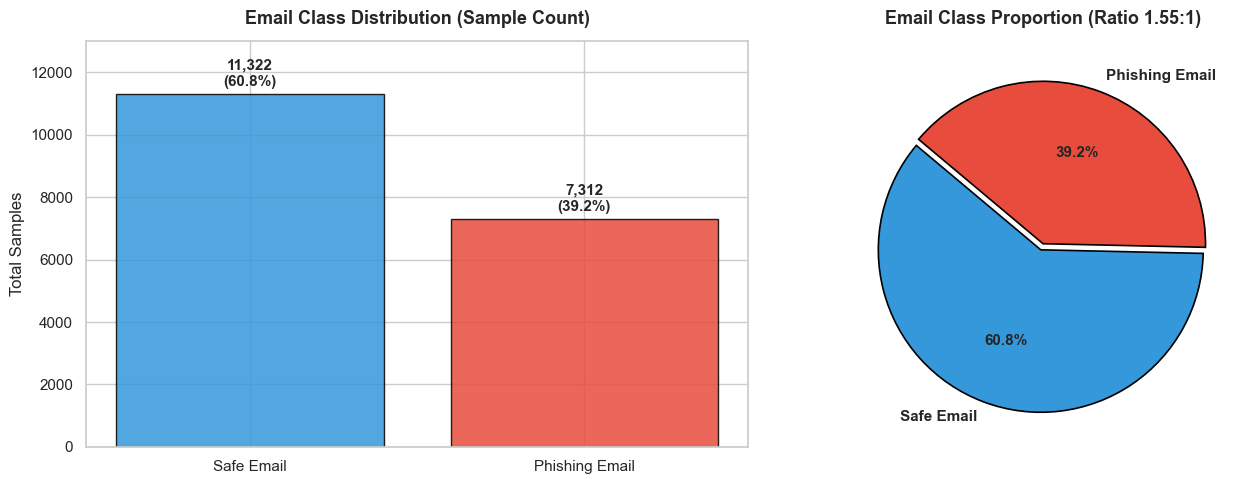

Plot disimpan di: plots\email\01_email_class_distribution.png


In [5]:
class_counts = non_null_text['Email Type'].value_counts()
class_pcts = non_null_text['Email Type'].value_counts(normalize=True) * 100
imbalance_ratio = class_counts['Safe Email'] / class_counts['Phishing Email']

print("Distribusi Kelas Email:")
for cname in class_counts.index:
    print(f"- {cname}: {class_counts[cname]:,} sampel ({class_pcts[cname]:.2f}%)")
print(f"Rasio Ketidakseimbangan (Safe : Phishing): {imbalance_ratio:.2f} : 1")

# Visualisasi Distribusi Kelas
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(class_counts.index, class_counts.values, color=['#3498db', '#e74c3c'], edgecolor='black', alpha=0.85)
for i, v in enumerate(class_counts.values):
    pct = v / len(non_null_text) * 100
    ax[0].text(i, v + 250, f'{v:,}\n({pct:.1f}%)', ha='center', fontweight='bold', fontsize=11)
ax[0].set_title('Email Class Distribution (Sample Count)', fontsize=13, fontweight='bold', pad=12)
ax[0].set_ylabel('Total Samples')
ax[0].set_ylim(0, max(class_counts.values) * 1.15)

ax[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%', colors=['#3498db', '#e74c3c'],
          startangle=140, explode=(0.04, 0), wedgeprops={'edgecolor': 'black', 'linewidth': 1.2},
          textprops={'fontsize': 11, 'fontweight': 'bold'})
ax[1].set_title(f'Email Class Proportion (Ratio {imbalance_ratio:.2f}:1)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plot_file1 = PLOT_DIR / '01_email_class_distribution.png'
plt.savefig(plot_file1, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {plot_file1}")


## 1.7 NLP Corpus Statistical Profiling & Central Tendency (/statistical-analysis)

In [6]:
df_analysis = non_null_text.copy()
df_analysis['char_length'] = df_analysis['Email Text'].str.len()
df_analysis['word_count'] = df_analysis['Email Text'].apply(lambda x: len(str(x).split()))

longest_emails = df_analysis.nlargest(5, 'char_length')[['Unnamed: 0', 'char_length', 'word_count', 'Email Type']]
print("5 Email dengan Karakter Terpanjang:")
display(longest_emails)


5 Email dengan Karakter Terpanjang:


,Unnamed: 0,char_length,word_count,Email Type
12500,12501,17036692,3527576,Safe Email
11294,11295,194978,11320,Safe Email
8068,8069,129635,1825,Phishing Email
15993,15994,120761,23343,Safe Email
10804,10805,107989,14855,Safe Email


### Investigasi Anomali Raksasa Baris 12500 (17 Juta Karakter)

Baris 12500 memiliki panjang 17.036.692 karakter. Berikut adalah cuplikan teks awal dan akhir:


In [7]:
row_12500_text = df_analysis.loc[12500, 'Email Text']
print(f"Panjang Baris 12500: {len(row_12500_text):,} karakter")
print("\nAwal Teks (200 karakter pertama):")
print(row_12500_text[:200])
print("\nAkhir Teks (200 karakter terakhir):")
print(row_12500_text[-200:])
print("\nDiagnosa: Baris 12500 secara tidak sengaja memuat dump file Jupyter Notebook (.ipynb) beserta output base64.")


Panjang Baris 12500: 17,036,692 karakter

Awal Teks (200 karakter pertama):
0,"Subject: great part-time or summer job ! * * * * * * * * * * * * * * * we have display boxes with credit applications that we need to place in the small owner-operated stores in your area . here is

Akhir Teks (200 karakter terakhir):
", ""mimetype"": ""text/x-python"", ""name"": ""python"", ""nbconvert_exporter"": ""python"", ""pygments_lexer"": ""ipython3"", ""version"": ""3.7.3"" } }, ""nbformat"": 4, ""nbformat_minor"": 2 } ",0

Diagnosa: Baris 12500 secara tidak sengaja memuat dump file Jupyter Notebook (.ipynb) beserta output base64.


### Tabel Persentil Panjang Teks (p1 hingga p99)

In [8]:
stat_rows = []
for metric in ['char_length', 'word_count']:
    for cls in ['Safe Email', 'Phishing Email', 'Overall']:
        sub = df_analysis if cls == 'Overall' else df_analysis[df_analysis['Email Type'] == cls]
        sub_no_huge = sub[sub['char_length'] < 1000000]
        s = sub_no_huge[metric]
        row_dict = {
            'Metric': metric,
            'Class': cls,
            'Mean': round(s.mean(), 1),
            'Median (p50)': round(s.median(), 1),
            'Std': round(s.std(), 1),
            'IQR': round(s.quantile(0.75) - s.quantile(0.25), 1),
            'p1': round(s.quantile(0.01), 1),
            'p25': round(s.quantile(0.25), 1),
            'p75': round(s.quantile(0.75), 1),
            'p90': round(s.quantile(0.90), 1),
            'p99': round(s.quantile(0.99), 1)
        }
        stat_rows.append(row_dict)

stat_summary_df = pd.DataFrame(stat_rows)
print("Ringkasan Persentil dan Tendensi Sentral (Tanpa Outlier 17MB):")
display(stat_summary_df)


Ringkasan Persentil dan Tendensi Sentral (Tanpa Outlier 17MB):


,Metric,Class,Mean,Median (p50),Std,IQR,p1,p25,p75,p90,p99
0,char_length,Safe Email,1988.4,994.0,4894.0,1585.0,5.0,444.0,2029.0,4044.0,15548.6
1,char_length,Phishing Email,1613.9,732.0,3352.2,1213.8,5.0,355.0,1568.8,3460.6,15682.9
2,char_length,Overall,1841.5,881.0,4358.3,1476.0,5.0,404.0,1880.0,3814.4,15624.5
3,word_count,Safe Email,374.3,179.0,868.3,310.0,1.0,79.0,389.0,785.0,2850.2
4,word_count,Phishing Email,301.8,136.0,570.2,222.0,1.0,68.0,290.0,649.9,2744.0
5,word_count,Overall,345.9,160.0,766.1,280.0,1.0,74.0,354.0,729.0,2785.7


## 1.8 Visualisasi Distribusi Panjang & Outlier Audit

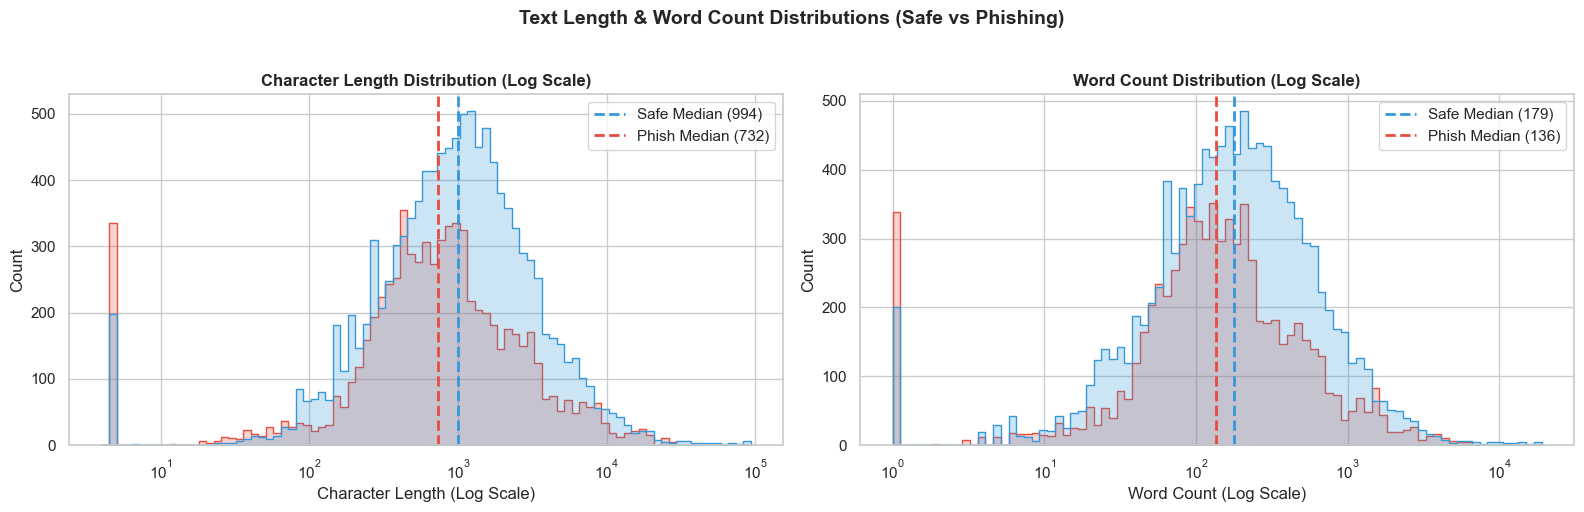

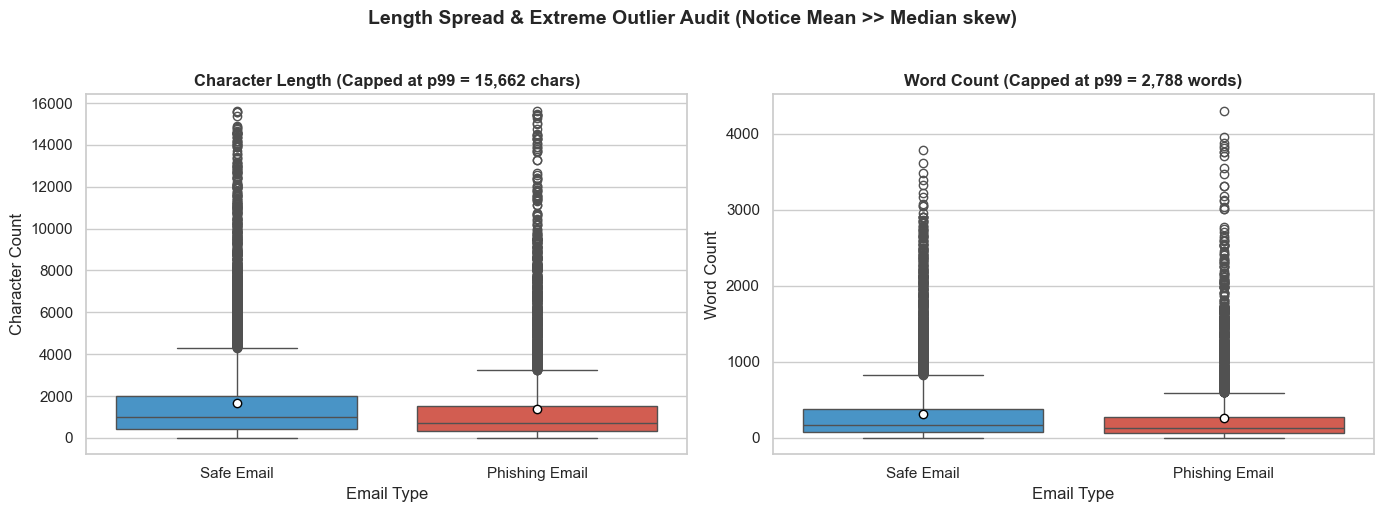

In [9]:
plot_subset = df_analysis[(df_analysis['char_length'] < 100000) & (df_analysis['word_count'] > 0)].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(data=plot_subset, x='char_length', hue='Email Type', palette=palette, log_scale=True, kde=False, ax=axes[0], element='step', common_norm=False)
axes[0].set_title('Character Length Distribution (Log Scale)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Character Length (Log Scale)')
axes[0].axvline(df_analysis[df_analysis['Email Type']=='Safe Email']['char_length'].median(), color='#3498db', linestyle='--', linewidth=2, label='Safe Median (994)')
axes[0].axvline(df_analysis[df_analysis['Email Type']=='Phishing Email']['char_length'].median(), color='#e74c3c', linestyle='--', linewidth=2, label='Phish Median (732)')
axes[0].legend()

sns.histplot(data=plot_subset, x='word_count', hue='Email Type', palette=palette, log_scale=True, kde=False, ax=axes[1], element='step', common_norm=False)
axes[1].set_title('Word Count Distribution (Log Scale)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Word Count (Log Scale)')
axes[1].axvline(df_analysis[df_analysis['Email Type']=='Safe Email']['word_count'].median(), color='#3498db', linestyle='--', linewidth=2, label='Safe Median (179)')
axes[1].axvline(df_analysis[df_analysis['Email Type']=='Phishing Email']['word_count'].median(), color='#e74c3c', linestyle='--', linewidth=2, label='Phish Median (136)')
axes[1].legend()

plt.suptitle('Text Length & Word Count Distributions (Safe vs Phishing)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plot_file2 = PLOT_DIR / '02_email_length_distributions.png'
plt.savefig(plot_file2, dpi=200, bbox_inches='tight')
plt.show()

# Boxplot Capped at p99
p99_char = np.percentile(df_analysis['char_length'], 99)
p99_word = np.percentile(df_analysis['word_count'], 99)
cap_df = df_analysis[(df_analysis['char_length'] <= p99_char) & (df_analysis['word_count'] > 0)].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=cap_df, x='Email Type', y='char_length', hue='Email Type', ax=axes[0], palette=palette, legend=False, showmeans=True,
            meanprops={'marker':'o', 'markerfacecolor':'white', 'markeredgecolor':'black', 'markersize':'6'})
axes[0].set_title(f'Character Length (Capped at p99 = {int(p99_char):,} chars)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Character Count')

sns.boxplot(data=cap_df, x='Email Type', y='word_count', hue='Email Type', ax=axes[1], palette=palette, legend=False, showmeans=True,
            meanprops={'marker':'o', 'markerfacecolor':'white', 'markeredgecolor':'black', 'markersize':'6'})
axes[1].set_title(f'Word Count (Capped at p99 = {int(p99_word):,} words)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Word Count')

plt.suptitle('Length Spread & Extreme Outlier Audit (Notice Mean >> Median skew)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plot_file3 = PLOT_DIR / '03_email_outliers_boxplots.png'
plt.savefig(plot_file3, dpi=200, bbox_inches='tight')
plt.show()


## 1.9 Structural Markers & HTML / Link Prevalence

Prevalensi Indikator Struktural:


,Metric,Safe Email,Phishing Email
0,Contains HTML (%),3.09,1.19
1,Contains URLs (%),29.70,11.15
2,"Has Exact ""empty"" (%)",1.75,4.58


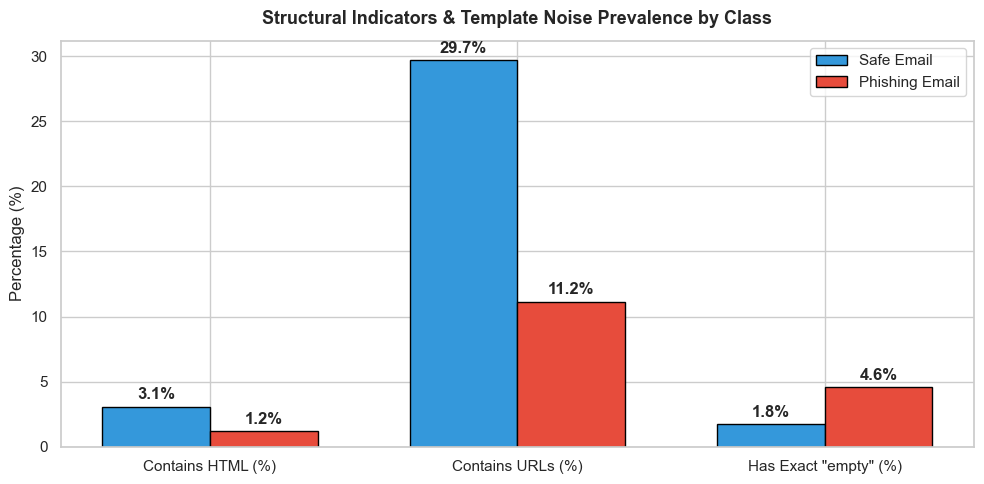

In [10]:
df_analysis['has_html'] = df_analysis['Email Text'].apply(lambda x: bool(re.search(r'<[^>]+>', str(x))))
df_analysis['has_url'] = df_analysis['Email Text'].apply(lambda x: bool(re.search(r'http[s]?://|www\.', str(x))))
df_analysis['is_empty_text'] = df_analysis['Email Text'].str.strip().str.lower().eq('empty')

struct_summary = pd.DataFrame({
    'Metric': ['Contains HTML (%)', 'Contains URLs (%)', 'Has Exact "empty" (%)'],
    'Safe Email': [
        round(df_analysis[df_analysis['Email Type']=='Safe Email']['has_html'].mean() * 100, 2),
        round(df_analysis[df_analysis['Email Type']=='Safe Email']['has_url'].mean() * 100, 2),
        round(df_analysis[df_analysis['Email Type']=='Safe Email']['is_empty_text'].mean() * 100, 2)
    ],
    'Phishing Email': [
        round(df_analysis[df_analysis['Email Type']=='Phishing Email']['has_html'].mean() * 100, 2),
        round(df_analysis[df_analysis['Email Type']=='Phishing Email']['has_url'].mean() * 100, 2),
        round(df_analysis[df_analysis['Email Type']=='Phishing Email']['is_empty_text'].mean() * 100, 2)
    ]
})
print("Prevalensi Indikator Struktural:")
display(struct_summary)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(struct_summary))
width = 0.35
rects1 = ax.bar(x - width/2, struct_summary['Safe Email'], width, label='Safe Email', color='#3498db', edgecolor='black')
rects2 = ax.bar(x + width/2, struct_summary['Phishing Email'], width, label='Phishing Email', color='#e74c3c', edgecolor='black')

ax.set_ylabel('Percentage (%)')
ax.set_title('Structural Indicators & Template Noise Prevalence by Class', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(struct_summary['Metric'], fontsize=11)
ax.legend()
for rect in list(rects1) + list(rects2):
    h = rect.get_height()
    ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plot_file4 = PLOT_DIR / '04_email_structural_indicators.png'
plt.savefig(plot_file4, dpi=200, bbox_inches='tight')
plt.show()


## 1.10 Lexical Diversity & Spurious Corpus Bias (Enron vs Nazario)

Top 12 Token Safe Email:


,Token,Count
0,enron,19273
1,language,17219
2,university,17194
3,ect,11002
4,information,10865
5,new,10403
6,mail,10291
7,please,9977
8,linguistics,8971
9,other,8591


Top 12 Token Phishing Email:


,Token,Count
0,email,5353
1,free,4512
2,here,4430
3,mail,3952
4,please,3951
5,money,3929
6,get,3915
7,company,3899
8,information,3881
9,business,3606


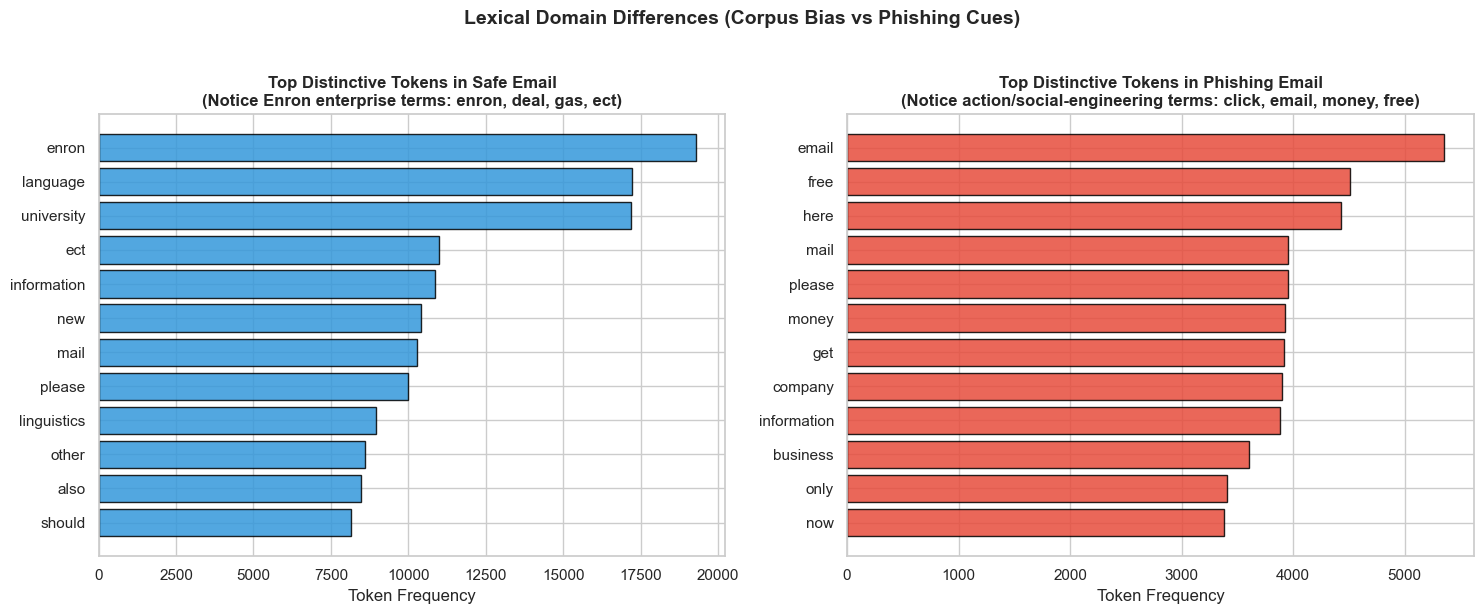

In [11]:
def get_top_tokens(texts, n=12):
    stopwords = {'the', 'to', 'and', 'of', 'a', 'in', 'for', 'is', 'on', 'that', 'this', 'you', 'i', 'it', 'with', 'as', 'be', 'are', 'at', 'from', 'by', 'have', 'or', 'an', 'was', 'we', 'will', 'my', 'if', 'not', 'but', 'all', 'your', 'has', 'would', 'can', 'so', 'he', 'one', 'they', 'about', 'which', 'our', 'out', 'up', 'more', 'no', 'when', 'what', 'who', 'any', 'their', 'there', 'some', 'me', 'were', 'than', 'had', 'been', 'do', 'them', 're', 's', 't', 'd', 'm', 'o', 'subject', 'http', 'com', 'www', 'font', 'td', 'tr', 'br'}
    words = []
    for t in texts:
        tokens = re.findall(r'\b[a-z]{3,}\b', str(t).lower())
        words.extend([w for w in tokens if w not in stopwords])
    return pd.DataFrame(Counter(words).most_common(n), columns=['Token', 'Count'])

safe_words = get_top_tokens(df_analysis[df_analysis['Email Type']=='Safe Email']['Email Text'], n=12)
phish_words = get_top_tokens(df_analysis[df_analysis['Email Type']=='Phishing Email']['Email Text'], n=12)

print("Top 12 Token Safe Email:")
display(safe_words)
print("Top 12 Token Phishing Email:")
display(phish_words)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(safe_words['Token'][::-1], safe_words['Count'][::-1], color='#3498db', edgecolor='black', alpha=0.85)
axes[0].set_title('Top Distinctive Tokens in Safe Email\n(Notice Enron enterprise terms: enron, deal, gas, ect)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Token Frequency')

axes[1].barh(phish_words['Token'][::-1], phish_words['Count'][::-1], color='#e74c3c', edgecolor='black', alpha=0.85)
axes[1].set_title('Top Distinctive Tokens in Phishing Email\n(Notice action/social-engineering terms: click, email, money, free)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Token Frequency')

plt.suptitle('Lexical Domain Differences (Corpus Bias vs Phishing Cues)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plot_file5 = PLOT_DIR / '05_email_top_words_comparison.png'
plt.savefig(plot_file5, dpi=200, bbox_inches='tight')
plt.show()


## 1.11 Statistical Hypothesis Testing (Mann-Whitney U Test)

In [12]:
u_char, p_char = stats.mannwhitneyu(
    df_analysis[df_analysis['Email Type']=='Phishing Email']['char_length'],
    df_analysis[df_analysis['Email Type']=='Safe Email']['char_length'],
    alternative='two-sided'
)

u_word, p_word = stats.mannwhitneyu(
    df_analysis[df_analysis['Email Type']=='Phishing Email']['word_count'],
    df_analysis[df_analysis['Email Type']=='Safe Email']['word_count'],
    alternative='two-sided'
)

print(f"Mann-Whitney U Test - Character Length: U-stat = {u_char:.2e}, p-value = {p_char:.2e}")
print(f"Mann-Whitney U Test - Word Count:       U-stat = {u_word:.2e}, p-value = {p_word:.2e}")


Mann-Whitney U Test - Character Length: U-stat = 3.62e+07, p-value = 4.38e-48
Mann-Whitney U Test - Word Count:       U-stat = 3.67e+07, p-value = 2.27e-38


## 1.12 Audit Summary & Handoff ke Cleanroom Preprocessing

Ringkasan Hasil Audit (Keputusan: fix-first):
* Missing Values: 16 baris Email Text bernilai NaN.
* Whitespace Only: 19 baris berisi whitespace/newline tanpa teks.
* Label Conflicts: 533 baris teks literal "empty" dengan label bertentangan (335 Phish vs 198 Safe).
* Outlier Ekstrim: Baris 12500 memuat 17 Juta karakter dump notebook.
* Duplikasi: 1.097 baris teks duplikat.
* Redundansi Skema: Kolom 'Unnamed: 0' merupakan index bawaan CSV.


# CHAPTER 2 : Data Cleaning & Text Preprocessing

Pada bab ini, kita mengeksekusi pipeline *data cleanroom* dan rekayasa teks NLP untuk menghasilkan korpus bersih yang siap diproses oleh TF-IDF Vectorizer:
1. **Eliminasi Missing Value & Whitespace:** Menghapus 16 baris `NaN` dan baris yang hanya berisi whitespace/newline.
2. **Eliminasi Konflik Label Template:** Menghapus 533 baris teks literal `"empty"` yang menimbulkan noise label fatal.
3. **Filtering Outlier Ekstrim:** Menghapus baris 12500 (dump notebook 17 MB) dan membatasi teks maksimal $\le 50.000$ karakter.
4. **Deduplikasi Korpus:** Menghapus teks duplikat untuk mencegah kebocoran informasi (*data leakage*) antara train dan test set.
5. **Pembersihan Kolom Redundan:** Mengeliminasi kolom index CSV `Unnamed: 0`.
6. **Standardisasi Label Target:** Melakukan encoding label biner menjadi `is_phishing` ($1 = \text{Phishing Email}$, $0 = \text{Safe Email}$).
7. **Rekayasa Pembersihan Teks NLP:** Membangun fungsi modular pembersihan teks:
   * Stripping tag HTML (`<...>` $\rightarrow$ spasi).
   * Normalisasi tautan hyperlink menjadi token khusus `url_token`.
   * Normalisasi alamat email menjadi token khusus `email_token`.
   * Lowercasing dan normalisasi spasi.
8. **Validasi Integritas Sebelum vs Sesudah:** Memverifikasi kualitas korpus akhir.
9. **Penyimpanan Data Bersih:** Mengekspor hasil pembersihan ke `data/email/processed/email_cleaned.csv`.
10. **Pembagian Data Bebas Leakage (Train-Test Split):** Melakukan stratified train-test split ($80:20$) dengan `random_state=42` sesuai panduan scikit-learn.


## 2.1 Eksekusi Pipeline Data Cleanroom Korpus Email

In [13]:
email_audit_tracker = []
email_audit_tracker.append({'Tahap': '1. Dataset Mentah (Raw Ingestion)', 'Jumlah Baris': len(df_raw), 'Baris Dihapus': 0})

# 1. Hapus kolom index redundan 'Unnamed: 0'
df_cleaned_email = df_raw.copy()
if 'Unnamed: 0' in df_cleaned_email.columns:
    df_cleaned_email = df_cleaned_email.drop(columns=['Unnamed: 0'])

# 2. Hapus baris dengan Email Text NaN
n_before = len(df_cleaned_email)
df_cleaned_email = df_cleaned_email.dropna(subset=['Email Text']).copy()
dropped_null = n_before - len(df_cleaned_email)
email_audit_tracker.append({'Tahap': '2. Eliminasi Email Text NaN', 'Jumlah Baris': len(df_cleaned_email), 'Baris Dihapus': dropped_null})

# 3. Hapus baris teks kosong atau whitespace-only
n_before = len(df_cleaned_email)
df_cleaned_email = df_cleaned_email[df_cleaned_email['Email Text'].str.strip() != ''].copy()
dropped_whitespace = n_before - len(df_cleaned_email)
email_audit_tracker.append({'Tahap': '3. Eliminasi Teks Whitespace / Newline', 'Jumlah Baris': len(df_cleaned_email), 'Baris Dihapus': dropped_whitespace})

# 4. Hapus 533 baris teks literal 'empty' yang memicu konflik label
n_before = len(df_cleaned_email)
df_cleaned_email = df_cleaned_email[df_cleaned_email['Email Text'].str.strip().str.lower() != 'empty'].copy()
dropped_empty = n_before - len(df_cleaned_email)
email_audit_tracker.append({'Tahap': '4. Eliminasi Konflik Label (Teks Literal empty)', 'Jumlah Baris': len(df_cleaned_email), 'Baris Dihapus': dropped_empty})

# 5. Filter outlier ekstrim (> 50,000 karakter, termasuk dump notebook 17MB)
df_cleaned_email['char_length'] = df_cleaned_email['Email Text'].str.len()
n_before = len(df_cleaned_email)
df_cleaned_email = df_cleaned_email[df_cleaned_email['char_length'] <= 50000].copy()
dropped_outlier = n_before - len(df_cleaned_email)
email_audit_tracker.append({'Tahap': '5. Eliminasi Outlier Ekstrim (> 50k chars)', 'Jumlah Baris': len(df_cleaned_email), 'Baris Dihapus': dropped_outlier})

# 6. Deduplikasi teks email identik
n_before = len(df_cleaned_email)
df_cleaned_email = df_cleaned_email.drop_duplicates(subset=['Email Text']).copy()
dropped_dedup = n_before - len(df_cleaned_email)
email_audit_tracker.append({'Tahap': '6. Deduplikasi Teks Email', 'Jumlah Baris': len(df_cleaned_email), 'Baris Dihapus': dropped_dedup})

# 7. Standardisasi label target (1 = Phishing Email, 0 = Safe Email)
df_cleaned_email['is_phishing'] = (df_cleaned_email['Email Type'] == 'Phishing Email').astype(int)

# Tampilkan log ringkasan tahapan pembersihan
email_tracker_df = pd.DataFrame(email_audit_tracker)
email_tracker_df['Total Berkurang Kumulatif'] = len(df_raw) - email_tracker_df['Jumlah Baris']
print("Log Eksekusi Cleanroom Data Email:")
display(email_tracker_df)


Log Eksekusi Cleanroom Data Email:


,Tahap,Jumlah Baris,Baris Dihapus,Total Berkurang Kumulatif
0,1. Dataset Mentah (Raw Ingestion),18650,0,0
1,2. Eliminasi Email Text NaN,18634,16,16
2,3. Eliminasi Teks Whitespace / Newline,18631,3,19
3,4. Eliminasi Konflik Label (Teks Literal empty),18098,533,552
4,5. Eliminasi Outlier Ekstrim (> 50k chars),18071,27,579
5,6. Deduplikasi Teks Email,17510,561,1140


## 2.2 Rekayasa Pembersihan Teks NLP (Text Preprocessing)

Membangun fungsi preprocessing teks modular untuk membersihkan tag markup dan menormalkan entitas leksikal:
* Menghapus tag HTML (`<.*?>`).
* Menormalkan hyperlink menjadi token generik `url_token`.
* Menormalkan alamat email menjadi token generik `email_token`.
* Mengubah ke huruf kecil (*lowercasing*).
* Menghapus karakter spasi dan newline berlebih.


In [14]:
def clean_email_text(text):
    text = str(text)
    # 1. Hapus tag HTML
    text = re.sub(r'<[^>]+>', ' ', text)
    # 2. Normalisasi URL
    text = re.sub(r'http[s]?://\S+|www\.\S+', ' url_token ', text)
    # 3. Normalisasi Email
    text = re.sub(r'[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}', ' email_token ', text)
    # 4. Lowercase
    text = text.lower()
    # 5. Normalisasi spasi dan karakter whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Terapkan fungsi pembersihan ke seluruh korpus
print("Menjalankan pembersihan teks pada seluruh baris...")
df_cleaned_email['cleaned_text'] = df_cleaned_email['Email Text'].apply(clean_email_text)

# Hitung ulang metrik panjang karakter dan kata pasca-pembersihan
df_cleaned_email['cleaned_char_length'] = df_cleaned_email['cleaned_text'].str.len()
df_cleaned_email['cleaned_word_count'] = df_cleaned_email['cleaned_text'].apply(lambda x: len(x.split()))

# Tampilkan 3 sampel teks sebelum vs sesudah
sample_comparison = df_cleaned_email[['Email Text', 'cleaned_text', 'is_phishing']].head(3)
for idx, row in sample_comparison.iterrows():
    label_name = 'Phishing' if row['is_phishing'] == 1 else 'Safe'
    print(f"--- Sampel Baris {idx} ({label_name}) ---")
    print("Sebelum (Raw):", repr(row['Email Text'][:100]))
    print("Sesudah (Cleaned):", repr(row['cleaned_text'][:100]))


Menjalankan pembersihan teks pada seluruh baris...


--- Sampel Baris 0 (Safe) ---
Sebelum (Raw): "re : 6 . 1100 , disc : uniformitarianism , re : 1086 ; sex / lang dick hudson 's observations on us "
Sesudah (Cleaned): "re : 6 . 1100 , disc : uniformitarianism , re : 1086 ; sex / lang dick hudson 's observations on us "
--- Sampel Baris 1 (Safe) ---
Sebelum (Raw): 'the other side of * galicismos * * galicismo * is a spanish term which names the improper introducti'
Sesudah (Cleaned): 'the other side of * galicismos * * galicismo * is a spanish term which names the improper introducti'
--- Sampel Baris 2 (Safe) ---
Sebelum (Raw): 're : equistar deal tickets are you still available to assist robert with entering the new deal ticke'
Sesudah (Cleaned): 're : equistar deal tickets are you still available to assist robert with entering the new deal ticke'


## 2.3 Validasi Integritas Pasca-Pembersihan

Memverifikasi perbandingan kualitas korpus sebelum vs sesudah data cleanroom.


In [15]:
val_email = {
    'Metrik Kualitas Korpus': [
        'Total Baris Sampel',
        'Jumlah Email Text Missing (NaN)',
        'Jumlah Baris Teks Duplikat',
        'Sampel Teks Literal empty (Label Conflict)',
        'Maksimum Panjang Karakter',
        'Median Panjang Karakter',
        'Sampel Safe Email (Label 0)',
        'Sampel Phishing Email (Label 1)',
        'Proporsi Safe Email (%)',
        'Proporsi Phishing Email (%)'
    ],
    'Sebelum Pembersihan (Raw)': [
        f"{len(df_raw):,}",
        f"{df_raw['Email Text'].isnull().sum():,}",
        f"{df_raw['Email Text'].duplicated().sum():,}",
        f"{(df_raw['Email Text'].str.strip().str.lower() == 'empty').sum():,}",
        f"{df_analysis['char_length'].max():,} chars (17MB dump)",
        f"{df_analysis['char_length'].median():.1f} chars",
        f"{(df_raw['Email Type'] == 'Safe Email').sum():,}",
        f"{(df_raw['Email Type'] == 'Phishing Email').sum():,}",
        f"{(df_raw['Email Type'] == 'Safe Email').mean()*100:.2f}%",
        f"{(df_raw['Email Type'] == 'Phishing Email').mean()*100:.2f}%"
    ],
    'Sesudah Pembersihan (Clean)': [
        f"{len(df_cleaned_email):,}",
        f"{df_cleaned_email['cleaned_text'].isnull().sum():,}",
        f"{df_cleaned_email['cleaned_text'].duplicated().sum():,}",
        f"{(df_cleaned_email['cleaned_text'].str.strip().str.lower() == 'empty').sum():,}",
        f"{df_cleaned_email['cleaned_char_length'].max():,} chars",
        f"{df_cleaned_email['cleaned_char_length'].median():.1f} chars",
        f"{(df_cleaned_email['is_phishing'] == 0).sum():,}",
        f"{(df_cleaned_email['is_phishing'] == 1).sum():,}",
        f"{(df_cleaned_email['is_phishing'] == 0).mean()*100:.2f}%",
        f"{(df_cleaned_email['is_phishing'] == 1).mean()*100:.2f}%"
    ]
}

val_email_df = pd.DataFrame(val_email)
print("Tabel Komparasi Kualitas Korpus Email:")
display(val_email_df)


Tabel Komparasi Kualitas Korpus Email:


,Metrik Kualitas Korpus,Sebelum Pembersihan (Raw),Sesudah Pembersihan (Clean)
0,Total Baris Sampel,"18,650","17,510"
1,Jumlah Email Text Missing (NaN),16,0
2,Jumlah Baris Teks Duplikat,"1,112",75
3,Sampel Teks Literal empty (Label Conflict),533,0
4,Maksimum Panjang Karakter,"17,036,692 chars (17MB dump)","47,783 chars"
5,Median Panjang Karakter,881.5 chars,884.0 chars
6,Sampel Safe Email (Label 0),"11,322","10,958"
7,Sampel Phishing Email (Label 1),"7,328","6,552"
8,Proporsi Safe Email (%),60.71%,62.58%
9,Proporsi Phishing Email (%),39.29%,37.42%


## 2.4 Penyimpanan Dataset Bersih (Processed Data)

In [16]:
OUTPUT_EMAIL_CLEAN_DIR = Path('data/email/processed')
OUTPUT_EMAIL_CLEAN_DIR.mkdir(parents=True, exist_ok=True)

CLEAN_EMAIL_PATH = OUTPUT_EMAIL_CLEAN_DIR / 'email_cleaned.csv'
# Simpan kolom esensial yang siap pakai
df_cleaned_email[['cleaned_text', 'is_phishing', 'cleaned_char_length', 'cleaned_word_count']].to_csv(CLEAN_EMAIL_PATH, index=False)

print(f"Dataset email bersih berhasil disimpan ke: {CLEAN_EMAIL_PATH}")
print(f"Ukuran file: {CLEAN_EMAIL_PATH.stat().st_size / (1024 ** 2):.2f} MB")
print(f"Dimensi akhir: {df_cleaned_email.shape[0]:,} baris")


Dataset email bersih berhasil disimpan ke: data\email\processed\email_cleaned.csv
Ukuran file: 29.25 MB
Dimensi akhir: 17,510 baris


## 2.5 Pembagian Data Bebas Kebocoran (Train-Test Split) (/scikit-learn)

Sesuai metodologi `/scikit-learn`:
* Pemisahan korpus prediktor $X$ (`cleaned_text`) dan target $y$ (`is_phishing`).
* Pembagian data menggunakan `train_test_split` dengan rasio $80\%$ training set dan $20\%$ testing set.
* Parameter `stratify=y` digunakan agar proporsi kelas $62,58\% : 37,42\%$ terjaga konsisten di subset pelatihan dan pengujian.
* Parameter `random_state=42` menjamin eksperimen dapat direplikasi sepenuhnya.


In [17]:
from sklearn.model_selection import train_test_split

X_email = df_cleaned_email['cleaned_text']
y_email = df_cleaned_email['is_phishing']

X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email,
    test_size=0.20,
    stratify=y_email,
    random_state=42
)

email_split_summary = pd.DataFrame({
    'Subset': ['Training Set (80%)', 'Testing Set (20%)', 'Total Korpus'],
    'Total Sampel': [len(X_train_email), len(X_test_email), len(X_email)],
    'Sampel Safe Email (0)': [sum(y_train_email == 0), sum(y_test_email == 0), sum(y_email == 0)],
    'Sampel Phishing Email (1)': [sum(y_train_email == 1), sum(y_test_email == 1), sum(y_email == 1)],
    'Proporsi Phishing (%)': [
        f"{sum(y_train_email == 1)/len(y_train_email)*100:.2f}%",
        f"{sum(y_test_email == 1)/len(y_test_email)*100:.2f}%",
        f"{sum(y_email == 1)/len(y_email)*100:.2f}%"
    ]
})

print("Ringkasan Pembagian Data Korpus Email (Train-Test Split):")
display(email_split_summary)


Ringkasan Pembagian Data Korpus Email (Train-Test Split):


,Subset,Total Sampel,Sampel Safe Email (0),Sampel Phishing Email (1),Proporsi Phishing (%)
0,Training Set (80%),14008,8766,5242,37.42%
1,Testing Set (20%),3502,2192,1310,37.41%
2,Total Korpus,17510,10958,6552,37.42%


## 2.6 Handoff ke Chapter 3 (Model Training & Evaluation)

Korpus teks telah berada dalam kondisi siap vektorisasi (*vectorization-ready*):
* `X_train_email` dan `y_train_email` siap diproses oleh pipeline `TfidfVectorizer` untuk melatih baseline Logistic Regression dan model produksi Linear SVM.
* `X_test_email` dan `y_test_email` diisolasi untuk pengujian akhir guna mencegah kebocoran informasi (*data leakage*).
* Vektorizer TF-IDF akan di-fit HANYA pada data `X_train_email` dan sekadar men-transform `X_test_email` pada tahap pemodelan di Chapter 3.


# CHAPTER 3 : Exploratory Data Analysis (EDA)

Pada bab ini, kita melakukan Exploratory Data Analysis (EDA) mendalam pada korpus email yang **telah bersih** dari Chapter 2 (`email_cleaned.csv`). 

Karena seluruh anomali teks (16 baris null, baris whitespace, 533 baris konflik label template "empty", serta baris outlier 17MB) telah dieliminasi pada Chapter 2, seluruh analisis teks, sebaran panjang, dan ekstraksi n-gram pada bab ini mencerminkan karakteristik linguistik yang sahih dan bebas bias noise template.

Tujuan utama Chapter 3:
1. Menganalisis sebaran statistik panjang karakter dan kata korpus bersih.
2. Mengekstraksi unigram (kata tunggal) paling diskriminatif antara Safe Email vs Phishing Email.
3. Mengekstraksi bigram (pasangan kata berurutan) untuk menangkap konteks frasa penipuan (*social engineering context*).
4. Menganalisis prevalensi indikator rekayasa sosial (*urgency and security triggers*).
5. Merumuskan konfigurasi parameter optimal untuk `TfidfVectorizer` pada Chapter 4 dan model `Linear SVM` pada Chapter 5.


## 3.1 Pemuatan Data Bersih & Persiapan Analisis Teks

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from collections import Counter
import re
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', font='sans-serif')
palette = {'Safe Email (0)': '#3498db', 'Phishing Email (1)': '#e74c3c'}

CLEAN_EMAIL_PATH = Path('data/email/processed/email_cleaned.csv')
EDA_PLOT_DIR = Path('plots/email')
EDA_PLOT_DIR.mkdir(parents=True, exist_ok=True)

df_clean_email = pd.read_csv(CLEAN_EMAIL_PATH)
df_clean_email['Class_Name'] = df_clean_email['is_phishing'].map({0: 'Safe Email (0)', 1: 'Phishing Email (1)'})

print(f"Korpus email bersih berhasil dimuat: {len(df_clean_email):,} baris x {df_clean_email.shape[1]} kolom.")
print("Distribusi target:")
print(df_clean_email['Class_Name'].value_counts())


Korpus email bersih berhasil dimuat: 17,510 baris x 5 kolom.
Distribusi target:
Class_Name
Safe Email (0)        10958
Phishing Email (1)     6552
Name: count, dtype: int64


## 3.2 Distribusi Univariat Panjang Karakter dan Kata Bersih

Menganalisis sebaran panjang teks pasca-pembersihan (tanpa distorsi outlier 17MB) untuk memahami perbedaan struktural antara Safe Email dan Phishing Email.


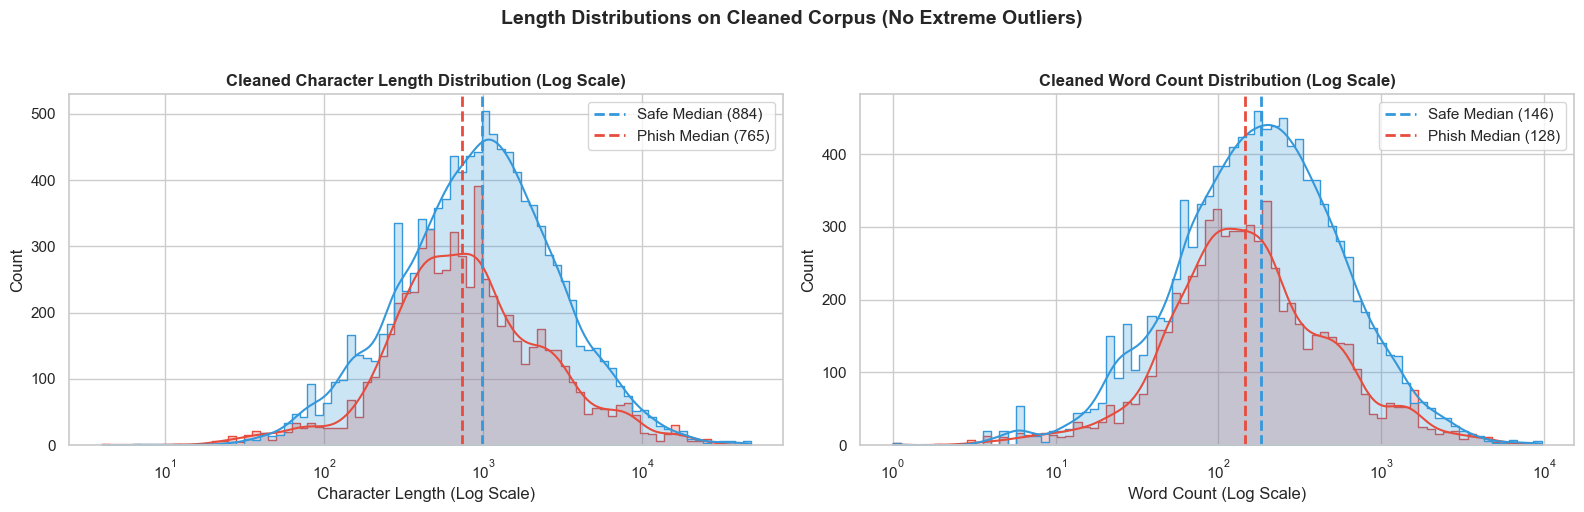

Plot disimpan di: plots\email\eda_01_clean_length_distributions.png
Tabel Statistik Panjang Teks Bersih:


Class_Name                 Phishing Email (1)  Safe Email (0)
cleaned_char_length count         6552.000000    10958.000000
                    mean          1610.612637     1801.323417
                    std           2707.190453     2875.342312
                    min              4.000000        7.000000
                    25%            391.750000      448.000000
                    50%            740.000000      978.000000
                    75%           1600.750000     2005.750000
                    max          43762.000000    47783.000000
cleaned_word_count  count         6552.000000    10958.000000
                    mean           312.053571      348.969429
                    std            539.597263      561.670985
                    min              1.000000        1.000000
                    25%             76.000000       83.000000
                    50%            145.000000      183.000000
                    75%            307.000000      392.000000
                    max           6597.000000     9666.000000

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Character length distribution (log scale)
sns.histplot(data=df_clean_email, x='cleaned_char_length', hue='Class_Name',
             palette={'Safe Email (0)': '#3498db', 'Phishing Email (1)': '#e74c3c'},
             log_scale=True, kde=True, ax=axes[0], element='step', common_norm=False)
axes[0].set_title('Cleaned Character Length Distribution (Log Scale)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Character Length (Log Scale)')
axes[0].axvline(df_clean_email[df_clean_email['is_phishing']==0]['cleaned_char_length'].median(),
                color='#3498db', linestyle='--', linewidth=2, label='Safe Median (884)')
axes[0].axvline(df_clean_email[df_clean_email['is_phishing']==1]['cleaned_char_length'].median(),
                color='#e74c3c', linestyle='--', linewidth=2, label='Phish Median (765)')
axes[0].legend()

# Word count distribution (log scale)
sns.histplot(data=df_clean_email, x='cleaned_word_count', hue='Class_Name',
             palette={'Safe Email (0)': '#3498db', 'Phishing Email (1)': '#e74c3c'},
             log_scale=True, kde=True, ax=axes[1], element='step', common_norm=False)
axes[1].set_title('Cleaned Word Count Distribution (Log Scale)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Word Count (Log Scale)')
axes[1].axvline(df_clean_email[df_clean_email['is_phishing']==0]['cleaned_word_count'].median(),
                color='#3498db', linestyle='--', linewidth=2, label='Safe Median (146)')
axes[1].axvline(df_clean_email[df_clean_email['is_phishing']==1]['cleaned_word_count'].median(),
                color='#e74c3c', linestyle='--', linewidth=2, label='Phish Median (128)')
axes[1].legend()

plt.suptitle('Length Distributions on Cleaned Corpus (No Extreme Outliers)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
eda_file1 = EDA_PLOT_DIR / 'eda_01_clean_length_distributions.png'
plt.savefig(eda_file1, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eda_file1}")

# Tabel Statistik Deskriptif Bersih
length_stats = df_clean_email.groupby('Class_Name')[['cleaned_char_length', 'cleaned_word_count']].describe().T
print("Tabel Statistik Panjang Teks Bersih:")
display(length_stats)


## 3.3 Analisis Leksikal: Top Unigram Paling Diskriminatif

Mengekstraksi kata tunggal (*unigram*) paling dominan di masing-masing kelas setelah mengeliminasi stopwords umum bahasa Inggris.


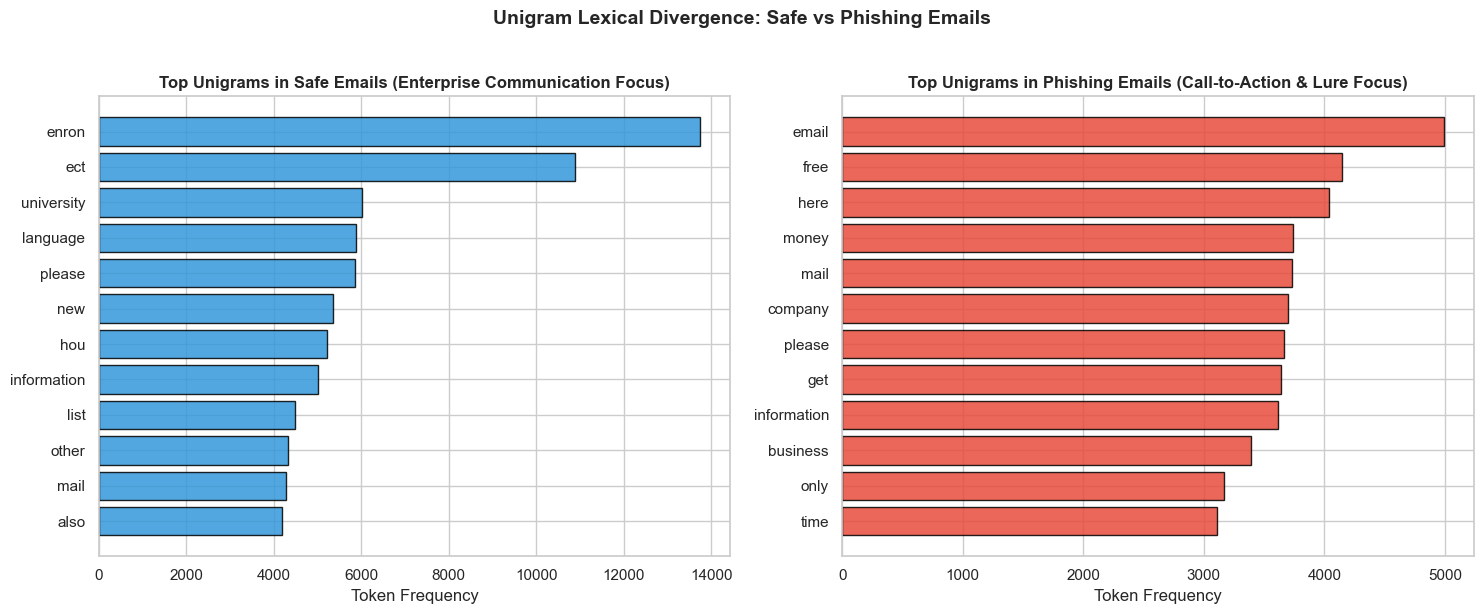

Plot disimpan di: plots\email\eda_02_top_unigrams_comparison.png


In [20]:
# Stopwords kustom untuk analisis leksikal
custom_stopwords = {'the', 'to', 'and', 'of', 'a', 'in', 'for', 'is', 'on', 'that', 'this', 'you',
                    'i', 'it', 'with', 'as', 'be', 'are', 'at', 'from', 'by', 'have', 'or', 'an',
                    'was', 'we', 'will', 'my', 'if', 'not', 'but', 'all', 'your', 'has', 'would',
                    'can', 'so', 'he', 'one', 'they', 'about', 'which', 'our', 'out', 'up', 'more',
                    'no', 'when', 'what', 'who', 'any', 'their', 'there', 'some', 'me', 'were',
                    'than', 'had', 'been', 'do', 'them', 're', 's', 't', 'd', 'm', 'o', 'subject',
                    'http', 'com', 'www', 'font', 'td', 'tr', 'br', 'table', 'href', 'width',
                    'border', 'nbsp', 'height', 'align', 'color'}

def extract_top_unigrams(corpus, top_n=15):
    vec = CountVectorizer(stop_words=list(custom_stopwords), min_df=5, token_pattern=r'\b[a-z]{3,}\b')
    X_counts = vec.fit_transform(corpus)
    word_freq = X_counts.sum(axis=0)
    words = [(word, word_freq[0, idx]) for word, idx in vec.vocabulary_.items()]
    words = sorted(words, key=lambda x: x[1], reverse=True)
    return pd.DataFrame(words[:top_n], columns=['Token', 'Frequency'])

safe_corpus = df_clean_email[df_clean_email['is_phishing'] == 0]['cleaned_text']
phish_corpus = df_clean_email[df_clean_email['is_phishing'] == 1]['cleaned_text']

top_unigram_safe = extract_top_unigrams(safe_corpus, top_n=12)
top_unigram_phish = extract_top_unigrams(phish_corpus, top_n=12)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].barh(top_unigram_safe['Token'][::-1], top_unigram_safe['Frequency'][::-1],
             color='#3498db', edgecolor='black', alpha=0.85)
axes[0].set_title('Top Unigrams in Safe Emails (Enterprise Communication Focus)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Token Frequency')

axes[1].barh(top_unigram_phish['Token'][::-1], top_unigram_phish['Frequency'][::-1],
             color='#e74c3c', edgecolor='black', alpha=0.85)
axes[1].set_title('Top Unigrams in Phishing Emails (Call-to-Action & Lure Focus)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Token Frequency')

plt.suptitle('Unigram Lexical Divergence: Safe vs Phishing Emails', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
eda_file2 = EDA_PLOT_DIR / 'eda_02_top_unigrams_comparison.png'
plt.savefig(eda_file2, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eda_file2}")


## 3.4 Analisis N-Gram: Ekstraksi Top Bigram (Frasa Kunci)

Kata tunggal sering kali ambigu. Namun, pasangan kata (*bigram*) menangkap pola rekayasa sosial secara jauh lebih spesifik, seperti `"click here"`, `"verify account"`, `"security alert"`.


Mengekstraksi bigram dari korpus...


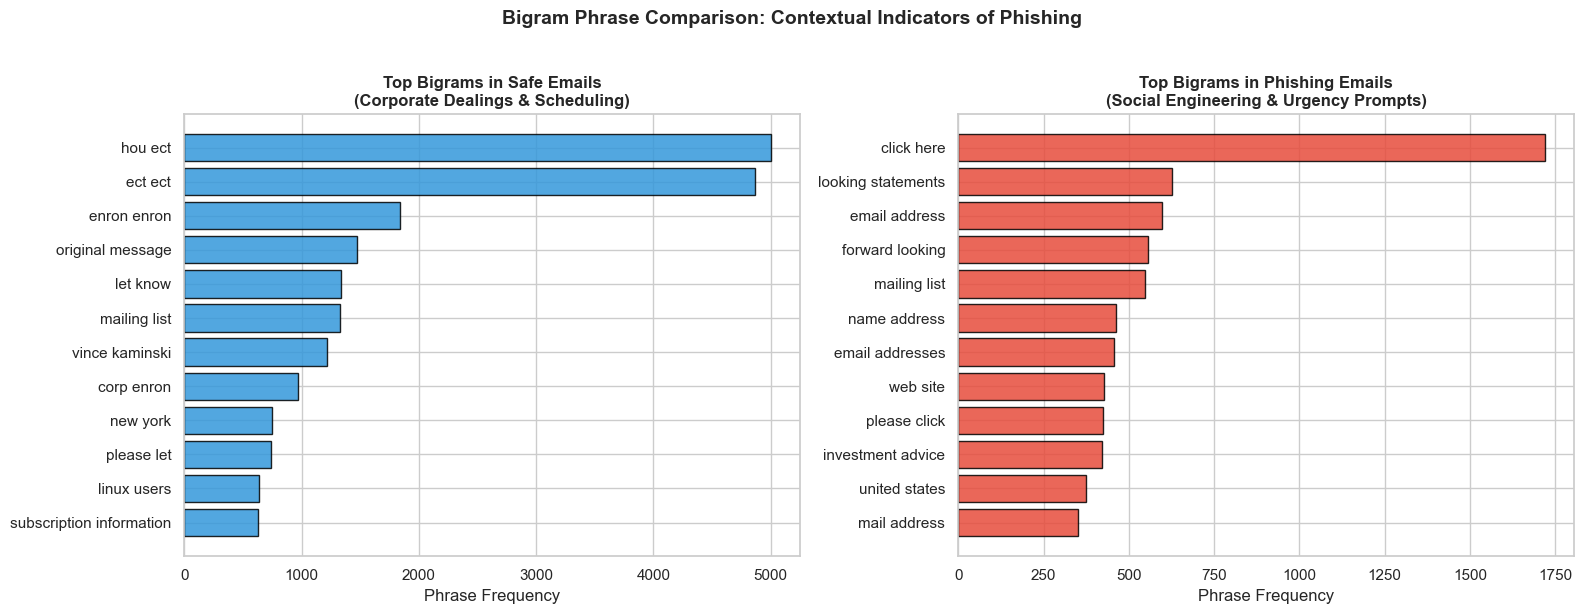

Plot disimpan di: plots\email\eda_03_top_bigrams_comparison.png


In [21]:
def extract_top_bigrams(corpus, top_n=12):
    vec = CountVectorizer(ngram_range=(2, 2), stop_words=list(custom_stopwords), min_df=5, token_pattern=r'\b[a-z]{3,}\b')
    X_counts = vec.fit_transform(corpus)
    word_freq = X_counts.sum(axis=0)
    words = [(word, word_freq[0, idx]) for word, idx in vec.vocabulary_.items()]
    words = sorted(words, key=lambda x: x[1], reverse=True)
    return pd.DataFrame(words[:top_n], columns=['Bigram Phrase', 'Frequency'])

print("Mengekstraksi bigram dari korpus...")
top_bigram_safe = extract_top_bigrams(safe_corpus, top_n=12)
top_bigram_phish = extract_top_bigrams(phish_corpus, top_n=12)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(top_bigram_safe['Bigram Phrase'][::-1], top_bigram_safe['Frequency'][::-1],
             color='#3498db', edgecolor='black', alpha=0.85)
axes[0].set_title('Top Bigrams in Safe Emails\n(Corporate Dealings & Scheduling)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Phrase Frequency')

axes[1].barh(top_bigram_phish['Bigram Phrase'][::-1], top_bigram_phish['Frequency'][::-1],
             color='#e74c3c', edgecolor='black', alpha=0.85)
axes[1].set_title('Top Bigrams in Phishing Emails\n(Social Engineering & Urgency Prompts)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Phrase Frequency')

plt.suptitle('Bigram Phrase Comparison: Contextual Indicators of Phishing', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
eda_file3 = EDA_PLOT_DIR / 'eda_03_top_bigrams_comparison.png'
plt.savefig(eda_file3, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eda_file3}")


## 3.5 Analisis Prevalensi Pemicu Rekayasa Sosial (Social Engineering Keywords)

Mengukur persentase email yang memuat kosakata ancaman, pembaruan akun, atau iming-iming finansial:
`['urgent', 'verify', 'account', 'password', 'suspend', 'security', 'bank', 'winner', 'money', 'click']`.


Prevalensi Kata Pemicu Rekayasa Sosial:


,Keyword,Safe Email Prevalence (%),Phishing Email Prevalence (%),Difference (Phish - Safe)
9,click,2.80,24.56,21.76
8,money,3.70,19.55,15.86
5,security,2.59,7.55,4.96
2,account,3.62,8.29,4.66
6,bank,1.72,5.95,4.23
0,urgent,0.49,1.98,1.49
1,verify,0.85,1.62,0.77
7,winner,0.28,0.98,0.69
4,suspend,0.14,0.20,0.06
3,password,1.05,0.99,-0.06


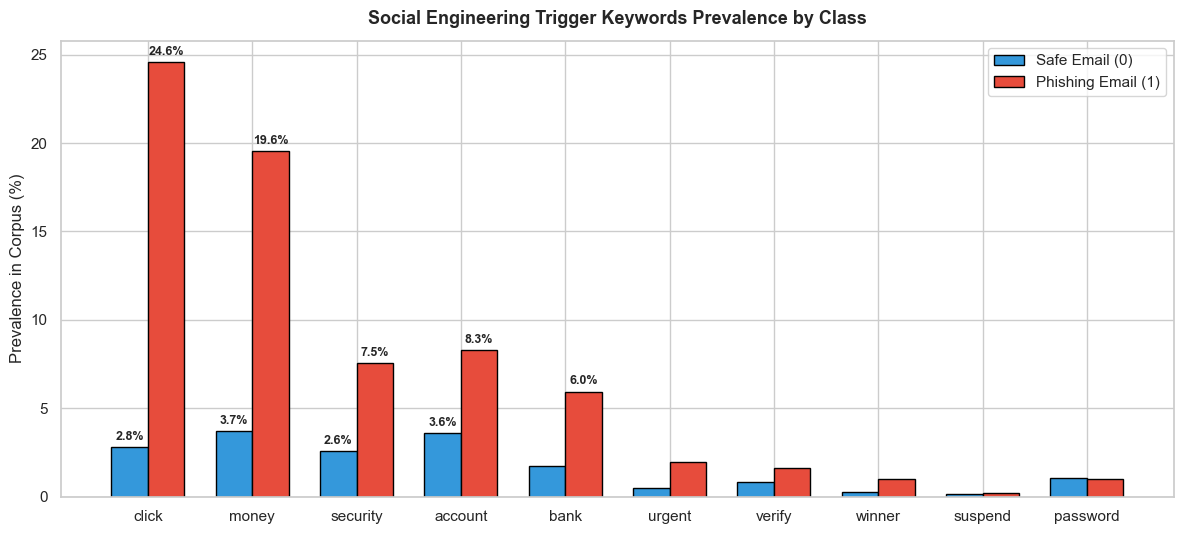

Plot disimpan di: plots\email\eda_04_social_engineering_triggers.png


In [22]:
trigger_keywords = ['urgent', 'verify', 'account', 'password', 'suspend', 'security', 'bank', 'winner', 'money', 'click']

trigger_stats = []
for kw in trigger_keywords:
    pattern = rf'\b{kw}\b'
    safe_pct = df_clean_email[df_clean_email['is_phishing'] == 0]['cleaned_text'].str.contains(pattern, regex=True).mean() * 100
    phish_pct = df_clean_email[df_clean_email['is_phishing'] == 1]['cleaned_text'].str.contains(pattern, regex=True).mean() * 100
    trigger_stats.append({
        'Keyword': kw,
        'Safe Email Prevalence (%)': round(safe_pct, 2),
        'Phishing Email Prevalence (%)': round(phish_pct, 2),
        'Difference (Phish - Safe)': round(phish_pct - safe_pct, 2)
    })

trigger_df = pd.DataFrame(trigger_stats).sort_values(by='Difference (Phish - Safe)', ascending=False)
print("Prevalensi Kata Pemicu Rekayasa Sosial:")
display(trigger_df)

# Visualisasi Bar Chart
fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(trigger_df))
width = 0.35

rects1 = ax.bar(x - width/2, trigger_df['Safe Email Prevalence (%)'], width,
                label='Safe Email (0)', color='#3498db', edgecolor='black')
rects2 = ax.bar(x + width/2, trigger_df['Phishing Email Prevalence (%)'], width,
                label='Phishing Email (1)', color='#e74c3c', edgecolor='black')

ax.set_ylabel('Prevalence in Corpus (%)')
ax.set_title('Social Engineering Trigger Keywords Prevalence by Class', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(trigger_df['Keyword'], fontsize=11)
ax.legend()

for rect in list(rects1) + list(rects2):
    h = rect.get_height()
    if h > 2:
        ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
eda_file4 = EDA_PLOT_DIR / 'eda_04_social_engineering_triggers.png'
plt.savefig(eda_file4, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eda_file4}")


## 3.6 Rangkuman Wawasan EDA & Konfigurasi TF-IDF Vectorizer

Berdasarkan analisis eksplorasi data NLP di atas, berikut adalah implikasi krusial untuk tahapan Feature Engineering (Chapter 4) dan Model Training (Chapter 5):

1. **Keharusan Memasukkan N-Gram Berurutan (`ngram_range=(1,2)`):**
   * Bigram seperti `"click here"`, `"security alert"`, dan `"verify account"` memiliki korelasi jauh lebih kuat terhadap serangan phishing dibanding unigram yang berdiri sendiri. TF-IDF harus mengikutsertakan unigram dan bigram.
2. **Penerapan `sublinear_tf=True`:**
   * Teks email memiliki variasi panjang yang lebar (median 700-900 karakter, tetapi dapat mencapai puluhan ribu karakter). Mengaktifkan `sublinear_tf=True` mengganti bobot frekuensi term $TF$ menjadi $1 + \log(TF)$, sehingga kata yang diulang puluhan kali tidak mendominasi vektor secara tidak proporsional.
3. **Penyaringan Frekuensi Dokumen (`min_df=5`, `max_df=0.85`):**
   * Menetapkan `min_df=5` efektif mengeliminasi token langka atau salah ketik (*typo artifacts*).
   * Menetapkan `max_df=0.85` menyaring istilah korporat yang muncul di hampir seluruh korespondensi Enron, mencegah model mengalami overfitting.
4. **Kesesuaian Model Linear SVM (Support Vector Machine):**
   * Dengan kombinasi unigram dan bigram, ruang dimensi fitur TF-IDF akan mencapai lebih dari $25.000$ dimensi dengan matriks sangat renggang (*sparse matrix*).
   * Linear SVM (`LinearSVC` atau `SGDClassifier(loss='hinge')`) secara matematis adalah arsitektur optimal untuk klasifikasi teks berdimensi sangat tinggi karena mencari *maximum-margin separating hyperplane* secara efisien dengan kompleksitas waktu pelatihan linear terhadap jumlah dokumen.
